In [ ]:
import pandas as pd

# Cargar el archivo CSV
df = pd.read_csv('/content/eu_limpio.csv')

# Mostrar las primeras filas del DataFrame
display(df.head())

,ID,Start_Date,End_Date,Duration,Category,Category_Kickstarter,Success,Funding,Funding_IHS,Target,...,Flag_IQR_Duration_Calendar,Flag_IQR_Description,Flag_IQR_Rewards,Flag_IQR_Prev_Success,Flag_IQR_Backed,Flag_IQR_Links,Category_Creative_Arts,Category_Design,Category_Literature_Journalism,Category_Food
0,4,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,2461.23,8.501564,1085.20,...,0,0,0,0,0,0,0,0,0,0
1,7,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,37601.09,11.227935,2170.40,...,0,0,0,0,1,0,0,0,0,0
2,12,2022-02-15,2022-03-07,20,Media & Entertainment,games,1,4531.80,9.112022,732.51,...,0,0,0,0,1,0,0,0,0,0
3,16,2022-02-17,2022-03-07,17,Media & Entertainment,games,1,18787.60,10.534100,5000.00,...,0,0,0,1,0,0,0,0,0,0
4,17,2022-02-04,2022-03-07,31,Media & Entertainment,film & video,0,1451.00,7.973156,3198.00,...,0,0,0,0,0,0,0,0,0,0


## Selección de variables y división de datos

Seleccionamos 11 características de las campañas para predecir su éxito con Random Forest. Excluimos variables del resultado final para evitar fuga de información. Dividimos los datos en 70 % para entrenamiento y 30 % para prueba, conservando la proporción de campañas exitosas y no exitosas.

In [ ]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

FEATURES = [
    "Category",
    "Target",
    "Duration",
    "Video_Header",
    "Videos_Bool",
    "Images_Bool",
    "Description",
    "Rewards",
    "Prev_Success",
    "Backed",
    "Links"
]

X = df[FEATURES].copy()
y = df["Success"].copy()

assert y.notna().all(), "Hay valores faltantes en Success"
assert set(y.unique()) == {0, 1}, "Success debe contener 0 y 1"

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Predictores:", len(FEATURES))
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

display(
    X_train.isna().sum().to_frame("Valores faltantes")
)

Predictores: 11
Entrenamiento: (1590, 11)
Prueba: (682, 11)


,Valores faltantes
Category,0
Target,0
Duration,0
Video_Header,0
Videos_Bool,0
Images_Bool,0
Description,0
Rewards,0
Prev_Success,0
Backed,0


## Preprocesamiento y preparación de Random Forest

Transformamos la categoría en columnas numéricas mediante codificación one-hot y preparamos el modelo Random Forest. No estandarizamos las variables porque este algoritmo no lo necesita. Configuramos una validación cruzada estratificada de cinco particiones para evaluar el modelo sin utilizar los datos de prueba.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

columnas_categoricas = ["Category"]

columnas_numericas = [
    columna for columna in FEATURES
    if columna not in columnas_categoricas
]

preprocesador = ColumnTransformer([
    ("numericas",
     SimpleImputer(strategy="median"),
     columnas_numericas),

    ("categoricas", Pipeline([
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("codificacion", OneHotEncoder(handle_unknown="ignore"))
    ]), columnas_categoricas)
])

pipeline_rf = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Pipeline de Random Forest preparado.")
print("Validación cruzada: 5 particiones estratificadas.")

Pipeline de Random Forest preparado.
Validación cruzada: 5 particiones estratificadas.


## Entrenamiento y ajuste de Random Forest

Comparamos ocho configuraciones de Random Forest mediante validación cruzada de cinco particiones. Seleccionamos la configuración con mayor ROC-AUC promedio y revisamos la diferencia entre entrenamiento y validación para detectar señales de sobreajuste. Mantenemos los datos de prueba reservados.

In [ ]:
from sklearn.model_selection import GridSearchCV

parametros_rf = {
    "modelo__n_estimators": [300],
    "modelo__max_depth": [None, 10],
    "modelo__min_samples_leaf": [1, 5],
    "modelo__class_weight": [None, "balanced"]
}

busqueda_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=parametros_rf,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

busqueda_rf.fit(X_train, y_train)

modelo_rf = busqueda_rf.best_estimator_
indice = busqueda_rf.best_index_

print("\nMejores parámetros:")
print(busqueda_rf.best_params_)

print(
    "\nROC-AUC promedio en validación:",
    round(busqueda_rf.best_score_, 4)
)

print(
    "Desviación estándar en validación:",
    round(busqueda_rf.cv_results_["std_test_score"][indice], 4)
)

print(
    "ROC-AUC promedio en entrenamiento:",
    round(busqueda_rf.cv_results_["mean_train_score"][indice], 4)
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Mejores parámetros:
{'modelo__class_weight': None, 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}

ROC-AUC promedio en validación: 0.8388
Desviación estándar en validación: 0.0304
ROC-AUC promedio en entrenamiento: 0.9542


## Evaluación de las clases mediante validación cruzada

Generamos predicciones para cada campaña de entrenamiento utilizando modelos que no la incluyeron en su ajuste. Aplicamos un umbral de 0,50 y revisamos las métricas y la matriz de confusión para ambas clases. Esta evaluación es orientativa porque reutilizamos las particiones empleadas para seleccionar los hiperparámetros. No utilizamos el conjunto de prueba.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

probabilidades_cv = cross_val_predict(
    clone(modelo_rf),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

predicciones_cv = (probabilidades_cv >= 0.50).astype(int)

print(classification_report(
    y_train,
    predicciones_cv,
    labels=[0, 1],
    target_names=["No exitosa", "Exitosa"],
    digits=3,
    zero_division=0
))

matriz_cv = pd.DataFrame(
    confusion_matrix(y_train, predicciones_cv, labels=[0, 1]),
    index=["Real: no exitosa", "Real: exitosa"],
    columns=["Predicción: no exitosa", "Predicción: exitosa"]
)

display(matriz_cv)

resumen_rf = pd.DataFrame([{
    "Modelo": "Random Forest",
    "ROC_AUC_CV": busqueda_rf.best_score_,
    "Exactitud_CV": accuracy_score(y_train, predicciones_cv),
    "Exactitud_balanceada_CV": balanced_accuracy_score(
        y_train, predicciones_cv
    ),
    "Precision_no_exitosa_CV": precision_score(
        y_train, predicciones_cv,
        pos_label=0, zero_division=0
    ),
    "Recall_no_exitosa_CV": recall_score(
        y_train, predicciones_cv,
        pos_label=0, zero_division=0
    ),
    "F1_macro_CV": f1_score(
        y_train, predicciones_cv,
        average="macro", zero_division=0
    )
}])

display(resumen_rf.round(4))

              precision    recall  f1-score   support

  No exitosa      0.726     0.281     0.405       292
     Exitosa      0.858     0.976     0.913      1298

    accuracy                          0.848      1590
   macro avg      0.792     0.628     0.659      1590
weighted avg      0.834     0.848     0.820      1590



,Predicción: no exitosa,Predicción: exitosa
Real: no exitosa,82,210
Real: exitosa,31,1267


,Modelo,ROC_AUC_CV,Exactitud_CV,Exactitud_balanceada_CV,Precision_no_exitosa_CV,Recall_no_exitosa_CV,F1_macro_CV
0,Random Forest,0.8388,0.8484,0.6285,0.7257,0.2808,0.659


## Interpretación de la validación y visualización

Obtenemos una exactitud de 84,84 %, pero una exactitud balanceada de 62,85 %. Identificamos correctamente 82 de las 292 campañas no exitosas y 1267 de las 1298 exitosas. Por tanto, el modelo favorece la identificación de campañas exitosas y presenta dificultades para detectar las no exitosas con el umbral de 0,50.

Representamos la matriz de confusión y la curva ROC para complementar la evaluación. Estos resultados son orientativos porque reutilizamos la validación empleada en el ajuste.

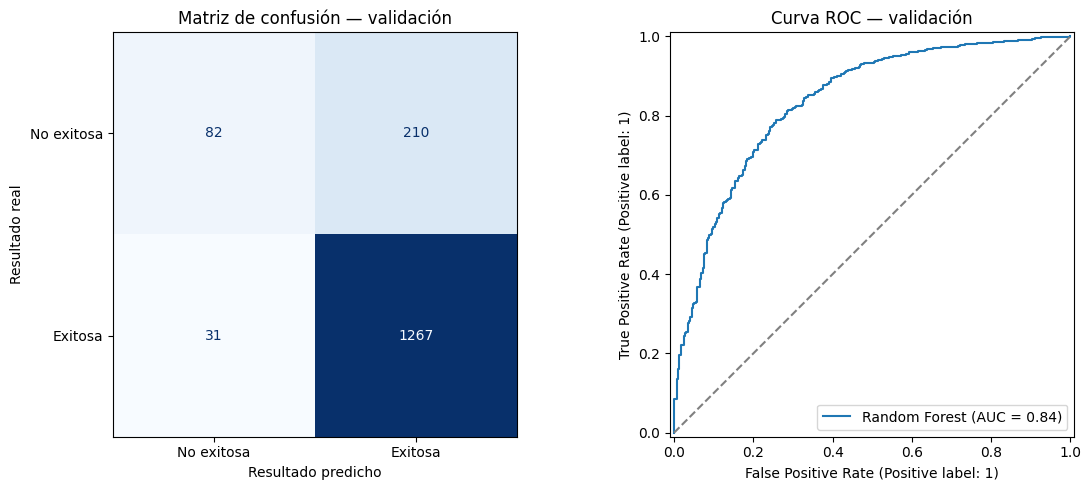

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    predicciones_cv,
    labels=[0, 1],
    display_labels=["No exitosa", "Exitosa"],
    cmap="Blues",
    colorbar=False,
    ax=ejes[0]
)
ejes[0].set_title("Matriz de confusión — validación")
ejes[0].set_xlabel("Resultado predicho")
ejes[0].set_ylabel("Resultado real")

RocCurveDisplay.from_predictions(
    y_train,
    probabilidades_cv,
    name="Random Forest",
    ax=ejes[1]
)
ejes[1].plot([0, 1], [0, 1], "--", color="gray")
ejes[1].set_title("Curva ROC — validación")

plt.tight_layout()
plt.show()

## Importancia de las variables

Calculamos la importancia interna de los predictores en Random Forest y agrupamos las columnas generadas para Category. Estas importancias describen cómo el modelo utiliza las variables durante el entrenamiento; no representan efectos causales ni garantizan su utilidad fuera de la muestra. Además, pueden favorecer variables con muchos valores posibles.

,Variable,Importancia_porcentaje
0,Target,39.43
7,Prev_Success,13.23
1,Duration,10.45
6,Rewards,9.08
8,Backed,8.14
5,Description,6.98
9,Links,4.92
10,Category,3.45
2,Video_Header,1.96
3,Videos_Bool,1.83


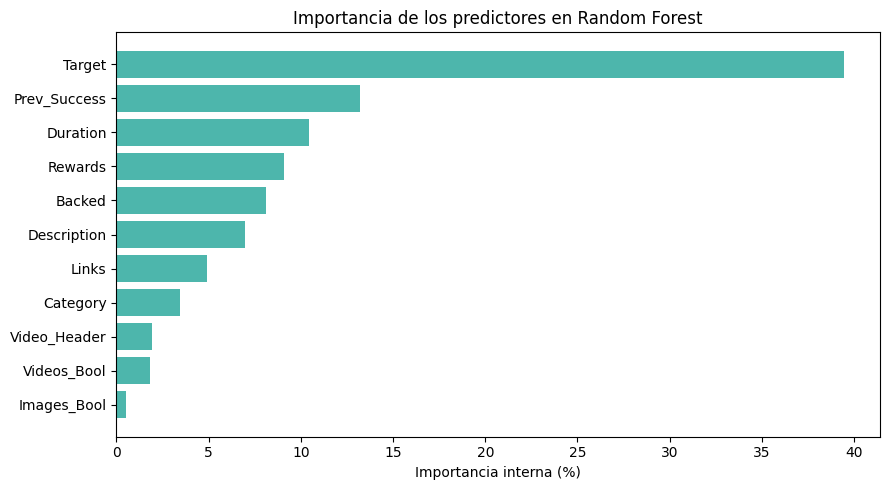

In [ ]:
import numpy as np

bosque = modelo_rf.named_steps["modelo"]
importancias = bosque.feature_importances_

# El preprocesador coloca primero las numéricas y luego Category
importancia_variables = pd.DataFrame({
    "Variable": columnas_numericas + ["Category"],
    "Importancia": np.concatenate([
        importancias[:len(columnas_numericas)],
        [importancias[len(columnas_numericas):].sum()]
    ])
}).sort_values("Importancia", ascending=False)

importancia_variables["Importancia_porcentaje"] = (
    importancia_variables["Importancia"] * 100
)

display(
    importancia_variables[
        ["Variable", "Importancia_porcentaje"]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    importancia_variables["Variable"],
    importancia_variables["Importancia_porcentaje"],
    color="#4DB6AC"
)

ax.invert_yaxis()
ax.set_xlabel("Importancia interna (%)")
ax.set_title("Importancia de los predictores en Random Forest")

plt.tight_layout()
plt.show()

## Interpretación de las variables y ejemplo de predicción

La meta solicitada, los éxitos previos del creador y la duración presentan las mayores importancias internas del modelo. Estos valores describen su participación en las decisiones del bosque, pero no representan efectos causales.

Mostramos una campaña real del entrenamiento con su predicción de validación cruzada. La probabilidad corresponde a un modelo que no utilizó esa campaña para entrenarse. Es un ejemplo ilustrativo y no una garantía de éxito.

In [ ]:
# Elegimos la primera campaña del conjunto de entrenamiento
posicion = 0

campaña_ejemplo = X_train.iloc[[posicion]].copy()
probabilidad = float(probabilidades_cv[posicion])
prediccion = int(probabilidad >= 0.50)
resultado_real = int(y_train.iloc[posicion])

display(campaña_ejemplo)

print(f"Probabilidad estimada de éxito: {probabilidad:.2%}")
print(
    "Predicción:",
    "Exitosa" if prediccion == 1 else "No exitosa"
)
print(
    "Resultado real:",
    "Exitosa" if resultado_real == 1 else "No exitosa"
)

,Category,Target,Duration,Video_Header,Videos_Bool,Images_Bool,Description,Rewards,Prev_Success,Backed,Links
460,Design,10034.0,60,1,0,1,21,4,1,3,1


Probabilidad estimada de éxito: 82.30%
Predicción: Exitosa
Resultado real: Exitosa


## Guardado del modelo y resultados

Guardamos el pipeline de Random Forest, los predictores, los índices de la partición y las métricas de validación para reproducir el análisis y facilitar su comparación con el otro modelo. Este archivo corresponde al modelo candidato; todavía no lo consideramos el modelo final del proyecto ni hemos evaluado el conjunto de prueba.

In [ ]:
import joblib
import sklearn
from google.colab import files

archivo_modelo = "random_forest_crowdfunding_candidato.joblib"

joblib.dump({
    "modelo": modelo_rf,
    "features": FEATURES,
    "umbral": 0.50,
    "random_state": RANDOM_STATE,
    "parametros": busqueda_rf.best_params_,
    "indices_train": X_train.index.tolist(),
    "indices_test": X_test.index.tolist(),
    "version_sklearn": sklearn.__version__,
    "estado": "Candidato pendiente de comparación y prueba final"
}, archivo_modelo)

resumen_rf.to_csv(
    "metricas_validacion_random_forest.csv",
    index=False
)

files.download(archivo_modelo)
files.download("metricas_validacion_random_forest.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Evaluación final en el conjunto de prueba

Evaluamos Random Forest en las 682 campañas reservadas, utilizando la configuración seleccionada mediante validación y un umbral de 0,50. Calculamos las métricas y la matriz de confusión sin realizar nuevos ajustes a partir de estos resultados.

              precision    recall  f1-score   support

  No exitosa      0.683     0.344     0.457       125
     Exitosa      0.868     0.964     0.913       557

    accuracy                          0.850       682
   macro avg      0.775     0.654     0.685       682
weighted avg      0.834     0.850     0.830       682



,Modelo,ROC_AUC,Exactitud,Exactitud_balanceada,Precision_no_exitosa,Recall_no_exitosa,F1_macro
0,Random Forest,0.8728,0.8504,0.654,0.6825,0.344,0.6854


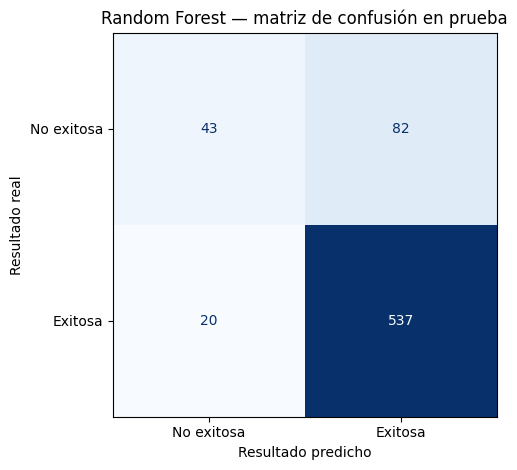

In [29]:
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

probabilidades_test = modelo_rf.predict_proba(X_test)[:, 1]
predicciones_test = (probabilidades_test >= 0.50).astype(int)

print(classification_report(
    y_test,
    predicciones_test,
    labels=[0, 1],
    target_names=["No exitosa", "Exitosa"],
    digits=3,
    zero_division=0
))

metricas_test = pd.DataFrame([{
    "Modelo": "Random Forest",
    "ROC_AUC": roc_auc_score(y_test, probabilidades_test),
    "Exactitud": accuracy_score(y_test, predicciones_test),
    "Exactitud_balanceada": balanced_accuracy_score(
        y_test, predicciones_test
    ),
    "Precision_no_exitosa": precision_score(
        y_test, predicciones_test,
        pos_label=0, zero_division=0
    ),
    "Recall_no_exitosa": recall_score(
        y_test, predicciones_test,
        pos_label=0, zero_division=0
    ),
    "F1_macro": f1_score(
        y_test, predicciones_test,
        average="macro", zero_division=0
    )
}])

display(metricas_test.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_test,
    labels=[0, 1],
    display_labels=["No exitosa", "Exitosa"],
    cmap="Blues",
    colorbar=False
)

plt.title("Random Forest — matriz de confusión en prueba")
plt.xlabel("Resultado predicho")
plt.ylabel("Resultado real")
plt.tight_layout()
plt.show()

## Preparación del modelo para el prototipo

Guardamos el pipeline entrenado de Random Forest junto con los predictores, las categorías admitidas y el umbral de clasificación. La interfaz cargará este archivo para generar predicciones sin volver a entrenar el modelo.

In [30]:
import joblib
import sklearn
from google.colab import files

archivo_modelo = "random_forest_crowdfunding.joblib"

paquete_modelo = {
    "modelo": modelo_rf,
    "features": FEATURES,
    "categorias": sorted(
        X_train["Category"].dropna().unique().tolist()
    ),
    "umbral": 0.50,
    "version_sklearn": sklearn.__version__
}

joblib.dump(paquete_modelo, archivo_modelo)

print("Modelo guardado.")
print("Versión de scikit-learn:", sklearn.__version__)

files.download(archivo_modelo)

Modelo guardado.
Versión de scikit-learn: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>